## Import and data load

In [1]:
import sys
import pandas as pd
from pathlib import Path

print(sys.executable)
print(sys.version)
print(pd.__version__)

pd.set_option('display.max_columns', None)

/home/mkukreja/Desktop/Docs/BRCA/brca1-risk-prediction/.venv/bin/python
3.14.7 | packaged by conda-forge | (main, Sep  2 2026, 21:09:07) [GCC 15.3.0]
3.0.6


In [2]:
df = pd.read_csv("../data/raw/dataset.csv")
df.shape

(1600, 24)

In [3]:
df.head()

,variation_id,gene_symbol,protein_change,protein_position,ref_aa,alt_aa,clinical_significance,domain,plddt,is_stop_gained,is_frameshift,is_splice_region,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta,domain_BRCT1,domain_BRCT2,domain_OTHER,domain_RING
0,100000,BRCA1,p.C176G,176,C,G,Benign,OTHER,61.795453,0,0,0,0,0.094471,67,52.778104,57.752886,2.9,0,48.4,False,False,True,False
1,100001,BRCA1,p.F773W,773,F,W,Benign,OTHER,50.859371,0,0,0,0,0.414922,664,59.417299,49.856908,3.7,0,37.9,False,False,True,False
2,100002,BRCA1,p.R1244W,1244,R,W,Benign,OTHER,54.256865,0,0,0,0,0.667740,402,46.864676,51.135601,3.6,1,54.4,False,False,True,False
3,100003,BRCA1,p.L36C,36,L,C,Pathogenic,RING,87.909717,0,0,0,1,0.019324,0,89.439383,83.145249,1.3,0,58.2,False,False,False,True
4,100004,BRCA1,p.I1205V,1205,I,V,Likely benign,OTHER,63.506025,0,0,0,0,0.646806,441,63.869783,56.117647,0.3,0,26.7,False,False,True,False


In [4]:
df.columns.tolist()

['variation_id',
 'gene_symbol',
 'protein_change',
 'protein_position',
 'ref_aa',
 'alt_aa',
 'clinical_significance',
 'domain',
 'plddt',
 'is_stop_gained',
 'is_frameshift',
 'is_splice_region',
 'label',
 'pos_norm',
 'distance_to_domain',
 'plddt_at_pos',
 'plddt_window11',
 'hydro_delta',
 'charge_delta',
 'volume_delta',
 'domain_BRCT1',
 'domain_BRCT2',
 'domain_OTHER',
 'domain_RING']

In [5]:
df.dtypes

variation_id               int64
gene_symbol                  str
protein_change               str
protein_position           int64
ref_aa                       str
alt_aa                       str
clinical_significance        str
domain                       str
plddt                    float64
is_stop_gained             int64
is_frameshift              int64
is_splice_region           int64
label                      int64
pos_norm                 float64
distance_to_domain         int64
plddt_at_pos             float64
plddt_window11           float64
hydro_delta              float64
charge_delta               int64
volume_delta             float64
domain_BRCT1                bool
domain_BRCT2                bool
domain_OTHER                bool
domain_RING                 bool
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   variation_id           1600 non-null   int64  
 1   gene_symbol            1600 non-null   str    
 2   protein_change         1600 non-null   str    
 3   protein_position       1600 non-null   int64  
 4   ref_aa                 1600 non-null   str    
 5   alt_aa                 1600 non-null   str    
 6   clinical_significance  1600 non-null   str    
 7   domain                 1600 non-null   str    
 8   plddt                  1600 non-null   float64
 9   is_stop_gained         1600 non-null   int64  
 10  is_frameshift          1600 non-null   int64  
 11  is_splice_region       1600 non-null   int64  
 12  label                  1600 non-null   int64  
 13  pos_norm               1600 non-null   float64
 14  distance_to_domain     1600 non-null   int64  
 15  plddt_at_pos   

## Data inspection

In [7]:
df.isnull().sum()

variation_id             0
gene_symbol              0
protein_change           0
protein_position         0
ref_aa                   0
alt_aa                   0
clinical_significance    0
domain                   0
plddt                    0
is_stop_gained           0
is_frameshift            0
is_splice_region         0
label                    0
pos_norm                 0
distance_to_domain       0
plddt_at_pos             0
plddt_window11           0
hydro_delta              0
charge_delta             0
volume_delta             0
domain_BRCT1             0
domain_BRCT2             0
domain_OTHER             0
domain_RING              0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

## categorical/value analysis

In [9]:
df["gene_symbol"].value_counts()

gene_symbol
BRCA1    1600
Name: count, dtype: int64

In [10]:
df["clinical_significance"].value_counts()

clinical_significance
Benign               559
Pathogenic           414
Likely benign        380
Likely pathogenic    247
Name: count, dtype: int64

In [11]:
df["label"].value_counts()

label
0    939
1    661
Name: count, dtype: int64

In [12]:
df["domain"].value_counts()

domain
OTHER    1337
RING       98
BRCT2      90
BRCT1      75
Name: count, dtype: int64

## Summary

In [13]:
df.describe()

,variation_id,protein_position,plddt,is_stop_gained,is_frameshift,is_splice_region,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta
count,1600.00000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000
mean,100799.50000,935.031875,57.626156,0.089375,0.101250,0.056250,0.413125,0.501896,307.230000,57.646664,57.518809,3.505313,0.476875,48.389312
std,462.02453,544.868609,15.257829,0.285373,0.301754,0.230476,0.492549,0.292468,244.411551,14.780929,13.564090,2.446875,0.568698,33.372782
min,100000.00000,1.000000,26.585780,0.000000,0.000000,0.000000,0.000000,0.000537,0.000000,27.900595,39.872967,0.000000,0.000000,0.000000
25%,100399.75000,443.750000,47.128614,0.000000,0.000000,0.000000,0.000000,0.238191,60.750000,47.582690,47.365507,1.400000,0.000000,23.900000
50%,100799.50000,955.500000,54.511761,0.000000,0.000000,0.000000,0.000000,0.512882,283.500000,53.973868,54.571564,3.000000,0.000000,49.400000
75%,101199.25000,1400.250000,63.506068,0.000000,0.000000,0.000000,1.000000,0.751610,517.000000,62.878395,59.915689,5.400000,1.000000,64.900000
max,101599.00000,1861.000000,98.000000,1.000000,1.000000,1.000000,1.000000,0.998926,767.000000,98.000000,93.290833,9.000000,2.000000,167.700000


In [14]:
# How many distinct values does each column contain?
df.nunique()

variation_id             1600
gene_symbol                 1
protein_change           1599
protein_position         1088
ref_aa                     20
alt_aa                     20
clinical_significance       4
domain                      4
plddt                    1585
is_stop_gained              2
is_frameshift               2
is_splice_region            2
label                       2
pos_norm                 1088
distance_to_domain        636
plddt_at_pos             1081
plddt_window11           1088
hydro_delta                84
charge_delta                3
volume_delta              168
domain_BRCT1                2
domain_BRCT2                2
domain_OTHER                2
domain_RING                 2
dtype: int64

In [15]:
# Which rows share the same protein change?
df[df["protein_change"].duplicated(keep=False)]

,variation_id,gene_symbol,protein_change,protein_position,ref_aa,alt_aa,clinical_significance,domain,plddt,is_stop_gained,is_frameshift,is_splice_region,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta,domain_BRCT1,domain_BRCT2,domain_OTHER,domain_RING
63,100063,BRCA1,p.S1191A,1191,S,A,Likely benign,OTHER,64.227355,0,0,0,0,0.639291,455,53.114076,55.983278,2.6,0,0.4,False,False,True,False
232,100232,BRCA1,p.S1191A,1191,S,A,Benign,OTHER,64.363177,0,0,0,0,0.639291,455,53.114076,55.983278,2.6,0,0.4,False,False,True,False


In [19]:
# duplicate positions and values
dup_positions=df['protein_position'].value_counts()
for p in dup_positions[dup_positions>1].head(5).index:
    print('pos',p)
    print(df[df.protein_position==p][['protein_change','plddt','plddt_at_pos','plddt_window11']].to_string(index=False))


pos 565
protein_change     plddt  plddt_at_pos  plddt_window11
       p.C565D 52.057817     59.736195       59.468901
       p.M565A 53.108812     59.736195       59.468901
       p.L565S 50.655145     59.736195       59.468901
       p.I565K 64.547312     59.736195       59.468901
       p.Y565C 62.933681     59.736195       59.468901
pos 1386
protein_change     plddt  plddt_at_pos  plddt_window11
      p.F1386I 41.277626     42.752513        44.40459
      p.M1386G 45.561580     42.752513        44.40459
      p.S1386E 36.715253     42.752513        44.40459
      p.V1386M 47.159529     42.752513        44.40459
      p.G1386F 41.799882     42.752513        44.40459
pos 730
protein_change     plddt  plddt_at_pos  plddt_window11
       p.D730T 60.341365     50.105482       54.571564
       p.Q730C 58.913555     50.105482       54.571564
       p.Q730L 61.032408     50.105482       54.571564
       p.S730W 55.975547     50.105482       54.571564
       p.K730V 51.577384     50.105482  

## Clinical annotation cross-tabs

In [16]:
# What percentage of rows has each clinical annotation?
df["clinical_significance"].value_counts(normalize=True).mul(100).round(2)

clinical_significance
Benign               34.94
Pathogenic           25.87
Likely benign        23.75
Likely pathogenic    15.44
Name: proportion, dtype: float64

In [17]:
# How do the clinical annotations correspond to the supplied labels?
pd.crosstab(df["clinical_significance"], df["label"])

label,0,1
clinical_significance,,
Benign,559,0
Likely benign,380,0
Likely pathogenic,0,247
Pathogenic,0,414


In [18]:
# How many rows of each clinical annotation occur in each domain?
pd.crosstab(df["domain"], df["clinical_significance"])

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
domain,,,,
BRCT1,14,7,19,35
BRCT2,14,18,25,33
OTHER,524,345,168,300
RING,7,10,35,46


In [19]:
# Within each domain, what percentage of rows has each clinical annotation?
pd.crosstab(df["domain"], df["clinical_significance"], normalize="index").mul(100).round(2)

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
domain,,,,
BRCT1,18.67,9.33,25.33,46.67
BRCT2,15.56,20.00,27.78,36.67
OTHER,39.19,25.80,12.57,22.44
RING,7.14,10.20,35.71,46.94


In [63]:
pd.crosstab(df["domain"],df["label"],normalize="index").round(3)

label,0,1
domain,,
BRCT1,0.280,0.720
BRCT2,0.356,0.644
OTHER,0.650,0.350
RING,0.173,0.827


In [20]:
# How are stop-gained annotations distributed across clinical annotations?
pd.crosstab(df["is_stop_gained"], df["clinical_significance"])

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
is_stop_gained,,,,
0,545,372,200,340
1,14,8,47,74


In [21]:
# How are frameshift annotations distributed across clinical annotations?
pd.crosstab(df["is_frameshift"], df["clinical_significance"])

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
is_frameshift,,,,
0,535,369,201,333
1,24,11,46,81


In [22]:
# How are splice-region annotations distributed across clinical annotations?
pd.crosstab(df["is_splice_region"], df["clinical_significance"])

clinical_significance,Benign,Likely benign,Likely pathogenic,Pathogenic
is_splice_region,,,,
0,551,373,219,367
1,8,7,28,47


## Numerical values by clinical annotation

In [23]:
# How does the supplied pLDDT distribution vary across clinical annotations?
df.groupby("clinical_significance")["plddt"].describe()

,count,mean,std,min,25%,50%,75%,max
clinical_significance,,,,,,,,
Benign,559.0,54.301632,11.852860,26.585780,47.036702,53.096044,59.619952,98.000000
Likely benign,380.0,54.590679,12.830910,32.591161,45.564835,52.359255,60.338343,95.966793
Likely pathogenic,247.0,63.038042,17.958719,30.386022,49.040014,58.254783,80.002838,98.000000
Pathogenic,414.0,61.672421,17.634247,32.050457,48.134277,55.670852,78.027986,98.000000


In [24]:
# What are the median supplied substitution deltas in each annotation group?
df.groupby("clinical_significance")[["hydro_delta", "charge_delta", "volume_delta"]].median()

,hydro_delta,charge_delta,volume_delta
clinical_significance,,,
Benign,2.8,0.0,39.10
Likely benign,2.8,0.0,40.45
Likely pathogenic,3.2,0.0,53.60
Pathogenic,3.4,0.0,51.00


In [15]:
# min/max positions by domain, distinct positions
df.groupby('domain')['protein_position'].agg(['min','max','count','nunique'])

,min,max,count,nunique
domain,,,,
BRCT1,1646,1736,75,55
BRCT2,1756,1855,90,61
OTHER,110,1861,1337,914
RING,1,109,98,58


## Basic plots

In [25]:
import matplotlib.pyplot as plt

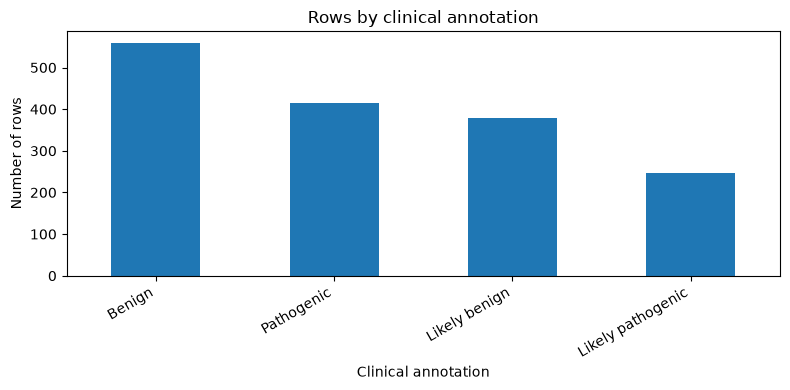

In [26]:
# How many rows belong to each clinical annotation?
df["clinical_significance"].value_counts().plot.bar(figsize=(8, 4))
plt.title("Rows by clinical annotation")
plt.xlabel("Clinical annotation")
plt.ylabel("Number of rows")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

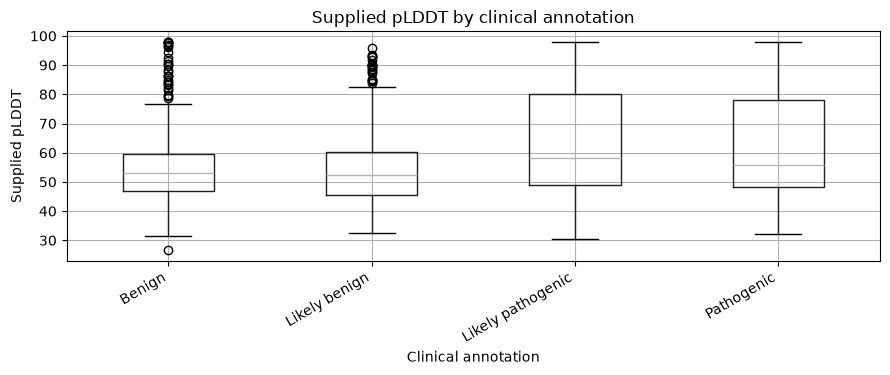

In [27]:
# How is supplied pLDDT distributed within each clinical annotation?
df.boxplot(column="plddt", by="clinical_significance", figsize=(9, 4))
plt.title("Supplied pLDDT by clinical annotation")
plt.suptitle("")
plt.xlabel("Clinical annotation")
plt.ylabel("Supplied pLDDT")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Domain-Specific analysis

In [24]:
pd.crosstab(df["domain"], df["protein_position"])

protein_position,1,5,7,8,9,11,13,14,18,19,...,1849,1850,1851,1853,1854,1855,1857,1859,1860,1861
domain,,,,,,,,,,,,,,,,,,,,,
BRCT1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BRCT2,0,0,0,0,0,0,0,0,0,0,...,3,2,2,1,2,1,0,0,0,0
OTHER,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,3,1,1,1
RING,1,2,2,2,1,2,2,2,1,2,...,0,0,0,0,0,0,0,0,0,0


**Protein Position and Domain Analysis**

BRCA1 is a large protein consisting of 1,863 amino acids.  
Each variant is mapped to a specific residue using `protein_position`.

The `domain` column groups protein positions into broader structural/functional regions:
- RING
- BRCT1
- BRCT2
- OTHER

How protein positions relate to these domain annotations before analyzing any relationship with pathogenicity.

In [25]:
domain_position_summary = (df.groupby("domain")["protein_position"].agg(["count", "nunique", "min", "max", "mean", "median"]).round(1))
domain_position_summary

,count,nunique,min,max,mean,median
domain,,,,,,
BRCT1,75,55,1646,1736,1693.3,1693.0
BRCT2,90,61,1756,1855,1805.9,1804.5
OTHER,1337,914,110,1861,898.2,903.0
RING,98,58,1,109,56.8,60.0


count - num of variant records in that domain <br>
nunique - num of distinct protein residues represented<br>

The domain summary shows that variants are not evenly distributed across BRCA1.

RING domain occurs near the N-terminal region of the protein, while BRCT1 and BRCT2 occur near the C-terminal region. Most variants in the dataset are categorized as `OTHER`, covering positions outside these specifically annotated domains.<br>

domain count != domain unique porotein residues<br>
meaning some positions contain more than one variant, multiple amino-acid substitutions can occur at the same residue.

In [37]:
pd.set_option('display.max_rows', None)

print(df.loc[df["protein_position"].between(98, 115),["protein_position", "domain"]].drop_duplicates().sort_values("protein_position"))
print("\n")
print(df.loc[df["protein_position"].between(1640, 1650),["protein_position", "domain"]].drop_duplicates().sort_values("protein_position"))
print("\n")
print(df.loc[df["protein_position"].between(1735, 1756),["protein_position", "domain"]].drop_duplicates().sort_values("protein_position"))

      protein_position domain
350                 99   RING
143                100   RING
12                 104   RING
1324               106   RING
1211               108   RING
86                 109   RING
255                110  OTHER
900                113  OTHER
207                115  OTHER


      protein_position domain
1492              1640  OTHER
441               1642  OTHER
1000              1643  OTHER
1414              1646  BRCT1
752               1649  BRCT1
857               1650  BRCT1


      protein_position domain
271               1735  BRCT1
24                1736  BRCT1
1229              1738  OTHER
72                1739  OTHER
585               1740  OTHER
1098              1743  OTHER
866               1746  OTHER
1532              1747  OTHER
164               1748  OTHER
1205              1749  OTHER
675               1750  OTHER
1129              1751  OTHER
293               1752  OTHER
652               1753  OTHER
920               1755  OTHER
838   

`OTEHR` is not a continuous protein domain.  
It represents positions that fall outside the 3 specifically encoded regions (RING, BRCT1, and BRCT2), so its minimum and maximum positions span several separate parts of the protein.

In [ ]:
domain_ranges = (df.groupby("domain").agg(n_variants=("variation_id", "count"),n_unique_positions=("protein_position", "nunique"),
                                          first_observed_position=("protein_position", "min"),last_observed_position=("protein_position", "max")))
domain_ranges

,n_variants,n_unique_positions,first_observed_position,last_observed_position
domain,,,,
BRCT1,75,55,1646,1736
BRCT2,90,61,1756,1855
OTHER,1337,914,110,1861
RING,98,58,1,109


**Normalized Protein Position**

BRCA1 protein contains 1,863 amino-acid residues.

`protein_position` represents the absolute residue number, ranging from the beginning (N-terminus) toward the end (C-terminus) of the protein.

The dataset also has `pos_norm`, which is the same location on a normalized 0–1 scale:


**pos_norm = protein_position / 1863**

So,:
- values close to 0 represent variants near the N-terminus,
- values close to 1 represent variants near the C-terminus.

`pos_norm` is therefore a scaled representation of protein position rather than an independent biological measurement.

In [45]:
df[["protein_position", "pos_norm"]].assign(calculated_pos_norm=df["protein_position"] / 1863).sample(10)

,protein_position,pos_norm,calculated_pos_norm
1297,726,0.389694,0.389694
557,873,0.468599,0.468599
51,824,0.442297,0.442297
377,399,0.214171,0.214171
1166,430,0.230811,0.230811
400,1148,0.616210,0.616210
945,1765,0.947397,0.947397
721,67,0.035963,0.035963
176,1472,0.790123,0.790123
476,1394,0.748256,0.748256


In [49]:
(df["pos_norm"] - (df["protein_position"] / 1863)).abs().max()

np.float64(1.1102230246251565e-16)

In [51]:
df.groupby("domain")["pos_norm"].agg(["min", "max", "mean", "median"]).round(6)

,min,max,mean,median
domain,,,,
BRCT1,0.883521,0.931830,0.908935,0.908749
BRCT2,0.942566,0.995706,0.969327,0.968599
OTHER,0.059045,0.998926,0.482152,0.484702
RING,0.000537,0.058508,0.030470,0.032206


### Domain specific plots

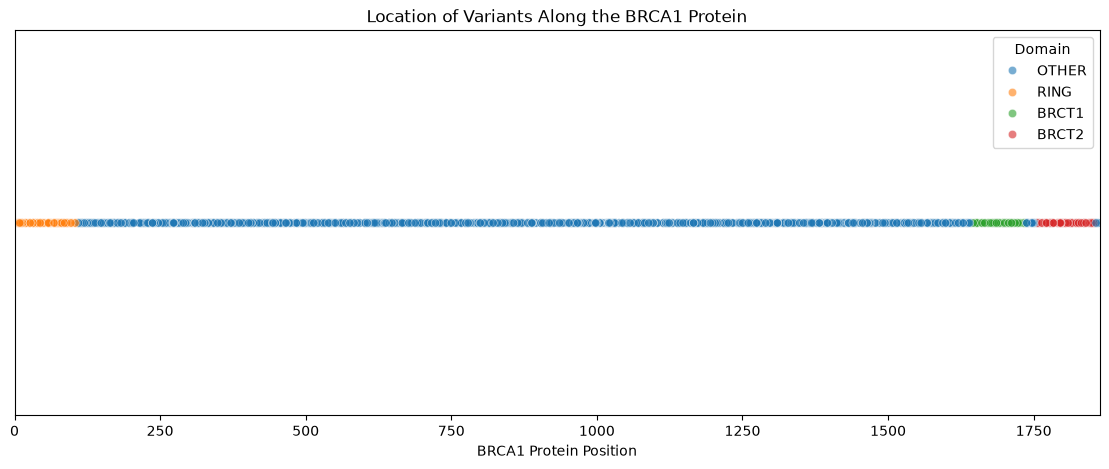

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
sns.scatterplot(data=df,x="protein_position",y=[1] * len(df),hue="domain",alpha=0.6)
plt.yticks([])
plt.xlim(0, 1863)
plt.xlabel("BRCA1 Protein Position")
plt.title("Location of Variants Along the BRCA1 Protein")
plt.legend(title="Domain")
plt.show()

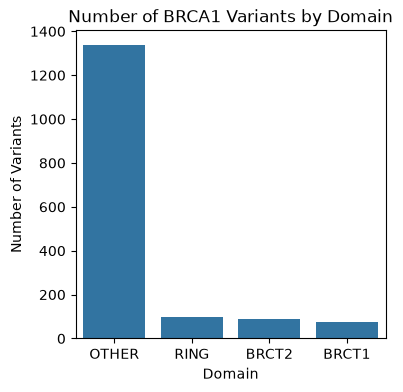

In [60]:
plt.figure(figsize=(4, 4))
sns.countplot(data=df,x="domain",order=df["domain"].value_counts().index)
plt.xlabel("Domain")
plt.ylabel("Number of Variants")
plt.title("Number of BRCA1 Variants by Domain")
plt.show()

In [ ]:
df[["protein_position", "domain", "distance_to_domain"]].sort_values("protein_position").head(20)

,protein_position,domain,distance_to_domain
258,1,RING,0
181,5,RING,0
383,5,RING,0
628,7,RING,0
216,7,RING,0
1085,8,RING,0
507,8,RING,0
1525,9,RING,0
1384,11,RING,0
301,11,RING,0


In [ ]:
df.groupby("domain")["distance_to_domain"].agg(["min", "max", "mean", "median"]).round(2)

,min,max,mean,median
domain,,,,
BRCT1,0,0,0.00,0.0
BRCT2,0,0,0.00,0.0
OTHER,1,767,367.66,358.0
RING,0,0,0.00,0.0


In [ ]:
df.loc[df["protein_position"].between(1725, 1765),["protein_position", "domain", "distance_to_domain"]].drop_duplicates().sort_values("protein_position")

,protein_position,domain,distance_to_domain
1189,1726,BRCT1,0
645,1728,BRCT1,0
1183,1732,BRCT1,0
1072,1733,BRCT1,0
85,1734,BRCT1,0
271,1735,BRCT1,0
24,1736,BRCT1,0
1229,1738,OTHER,2
72,1739,OTHER,3
585,1740,OTHER,4


### pLDDT Analysis

predicted Local Distance Difference Test - measure of AlphaFold's confidence in its local protein model geometry (structural prediction confidence)

**pLDDT range: 0 to 100**

Higher pLDDT: greater confidence in the predicted local protein structure. <br>
Lower pLDDT:  lower structural confidence; may also occur in flexible or intrinsically disordered protein regions.

In [77]:
df[["plddt", "plddt_at_pos", "plddt_window11"]].describe()

,plddt,plddt_at_pos,plddt_window11
count,1600.000000,1600.000000,1600.000000
mean,57.626156,57.646664,57.518809
std,15.257829,14.780929,13.564090
min,26.585780,27.900595,39.872967
25%,47.128614,47.582690,47.365507
50%,54.511761,53.973868,54.571564
75%,63.506068,62.878395,59.915689
max,98.000000,98.000000,93.290833


In [76]:
df[["protein_position","protein_change","domain","plddt","plddt_at_pos","plddt_window11"]].head(10)

,protein_position,protein_change,domain,plddt,plddt_at_pos,plddt_window11
0,176,p.C176G,OTHER,61.795453,52.778104,57.752886
1,773,p.F773W,OTHER,50.859371,59.417299,49.856908
2,1244,p.R1244W,OTHER,54.256865,46.864676,51.135601
3,36,p.L36C,RING,87.909717,89.439383,83.145249
4,1205,p.I1205V,OTHER,63.506025,63.869783,56.117647
5,332,p.W332R,OTHER,43.243576,43.476604,45.877090
6,1653,p.T1653F,BRCT1,84.702150,90.494384,91.529545
7,1033,p.E1033T,OTHER,56.508104,55.980145,55.209197
8,1630,p.W1630G,OTHER,48.279906,58.053104,58.717517
9,381,p.Q381L,OTHER,46.250027,49.492464,44.857150


In [79]:
pos_counts = df["protein_position"].value_counts()
repeated_pos = pos_counts[pos_counts > 1]
repeated_pos.head(10)

protein_position
565     5
1386    5
730     5
110     5
230     5
1606    4
1275    4
1528    4
1457    4
1191    4
Name: count, dtype: int64

In [ ]:
position = repeated_pos.index[0]
df.loc[df["protein_position"] == position, ["protein_change","protein_position","plddt","plddt_at_pos","plddt_window11"]]

,protein_change,protein_position,plddt,plddt_at_pos,plddt_window11
39,p.C565D,565,52.057817,59.736195,59.468901
142,p.M565A,565,53.108812,59.736195,59.468901
513,p.L565S,565,50.655145,59.736195,59.468901
1157,p.I565K,565,64.547312,59.736195,59.468901
1196,p.Y565C,565,62.933681,59.736195,59.468901


for protein_pos 565, plddt_at_pos, plddt_window11 are same, but plddt is different

In [82]:
# Within any single protein position, how many different values can each structural variable have?
df.groupby("protein_position")[["plddt", "plddt_at_pos", "plddt_window11"]].nunique().max()

plddt             5
plddt_at_pos      1
plddt_window11    1
dtype: int64

Its just the plddt that varries for any protein position

In [83]:
# how many protein positions have multiple values:
plddt_variation_by_position = (df.groupby("protein_position")[["plddt", "plddt_at_pos", "plddt_window11"]].nunique())
(plddt_variation_by_position > 1).sum()

plddt             378
plddt_at_pos        0
plddt_window11      0
dtype: int64

For repeated protein positions, `plddt_at_pos` and `plddt_window11` remain constant, but `plddt` value varies across variants.

`plddt_at_pos` and `plddt_window11` seem to be directly associated to protein position and local structural context.

`plddt` seems to contain variant-level information

In [84]:
position_plddt = (df[["protein_position", "domain", "plddt_at_pos"]].drop_duplicates().sort_values("protein_position"))
position_plddt.head()

,protein_position,domain,plddt_at_pos
258,1,RING,84.228334
181,5,RING,72.841911
216,7,RING,78.063234
507,8,RING,89.028046
1525,9,RING,73.305762


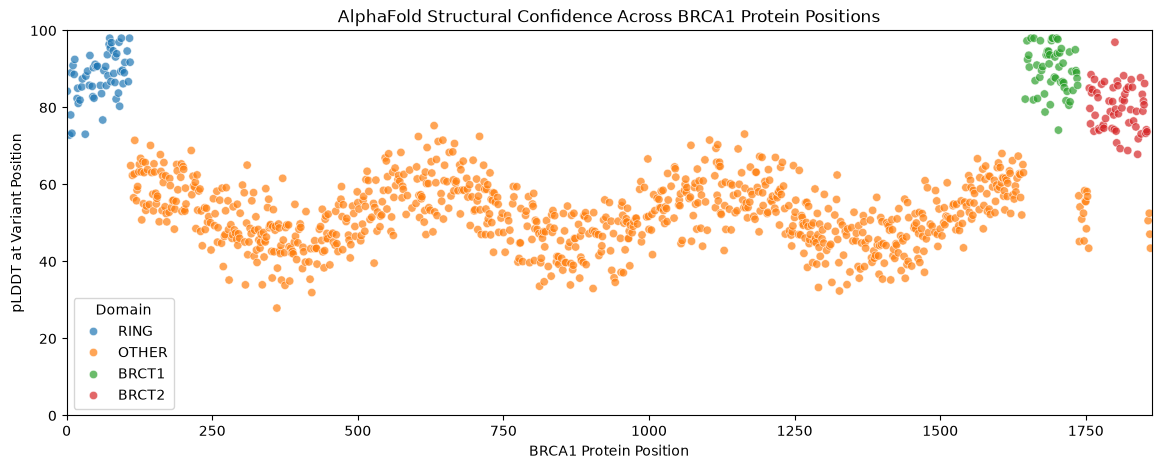

In [85]:
plt.figure(figsize=(14, 5))
sns.scatterplot(data=position_plddt,x="protein_position",y="plddt_at_pos",hue="domain",alpha=0.7)
plt.xlim(0, 1863)
plt.ylim(0, 100)
plt.xlabel("BRCA1 Protein Position")
plt.ylabel("pLDDT at Variant Position")
plt.title("AlphaFold Structural Confidence Across BRCA1 Protein Positions")
plt.legend(title="Domain")
plt.show()

`plddt_window11` (based on its name) - structural confidence over an 11-residue local window centered around the variant position {just my inference based on the column name}

In [ ]:
df[["protein_position","plddt_at_pos","plddt_window11"]].drop_duplicates().head(15)

,protein_position,plddt_at_pos,plddt_window11
0,176,52.778104,57.752886
1,773,59.417299,49.856908
2,1244,46.864676,51.135601
3,36,89.439383,83.145249
4,1205,63.869783,56.117647
5,332,43.476604,45.877090
6,1653,90.494384,91.529545
7,1033,55.980145,55.209197
8,1630,58.053104,58.717517
9,381,49.492464,44.857150


In [87]:
plddt_comparison = df[["protein_position","plddt_at_pos","plddt_window11"]].drop_duplicates().copy()
plddt_comparison["window_difference"] = (plddt_comparison["plddt_at_pos"] - plddt_comparison["plddt_window11"])
plddt_comparison[["plddt_at_pos", "plddt_window11", "window_difference"]].describe().round(2)

,plddt_at_pos,plddt_window11,window_difference
count,1088.00,1088.00,1088.00
mean,57.49,57.37,0.12
std,14.65,13.35,5.78
min,27.90,39.87,-22.68
25%,47.70,47.51,-3.82
50%,53.98,54.41,0.16
75%,62.51,59.73,3.87
max,98.00,93.29,17.60


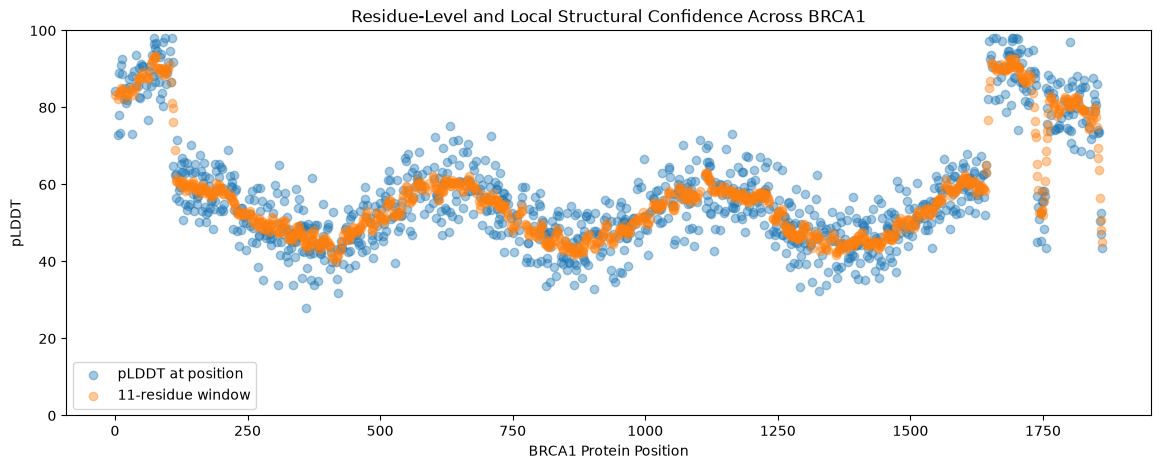

In [ ]:
plt.figure(figsize=(14, 5))
plt.scatter(plddt_comparison["protein_position"],plddt_comparison["plddt_at_pos"],alpha=0.4,label="pLDDT at position")
plt.scatter(plddt_comparison["protein_position"],plddt_comparison["plddt_window11"],alpha=0.4,label="11-residue window")
plt.xlabel("BRCA1 Protein Position")
plt.ylabel("pLDDT")
plt.title("Residue-Level and Local Structural Confidence Across BRCA1")
plt.ylim(0, 100)
plt.legend()
plt.show()

In [91]:
position_structure = df[["protein_position","domain","plddt_at_pos", "plddt_window11"]].drop_duplicates()
position_structure.groupby("domain")[["plddt_at_pos", "plddt_window11"]].agg(["mean", "median", "min", "max"]).round(2)

plddt_at_pos                      plddt_window11                     
               mean median    min    max           mean median    min    max
domain                                                                      
BRCT1         89.76  90.49  74.12  98.00          88.41  89.99  72.24  92.80
BRCT2         79.79  79.56  67.84  96.96          78.84  79.97  63.83  82.87
OTHER         52.13  52.12  27.90  75.29          52.16  51.83  39.87  76.35
RING          87.92  88.71  72.84  98.00          87.54  87.87  79.82  93.29

Inference:

`RING` and `BRCT1` - higher pLDDT values (mean = 88-90)<br>
`BRCT2`  - relatively lower pLDDT values (mean = approx 80)<br>
`OTHER` - significantly lower average pLDDT values (approx 52)

### Amino-Acid substitutions related cols

- `hydro_delta`: change in hydrophobic character
- `charge_delta`: change in electrical charge
- `volume_delta`: change in amino-acid side-chain volume

These features describe different physicochemical consequences of the same amino-acid substitution.

In [92]:
df[["protein_change","protein_position","ref_aa","alt_aa","hydro_delta","charge_delta","volume_delta"]].head(10)

,protein_change,protein_position,ref_aa,alt_aa,hydro_delta,charge_delta,volume_delta
0,p.C176G,176,C,G,2.9,0,48.4
1,p.F773W,773,F,W,3.7,0,37.9
2,p.R1244W,1244,R,W,3.6,1,54.4
3,p.L36C,36,L,C,1.3,0,58.2
4,p.I1205V,1205,I,V,0.3,0,26.7
5,p.W332R,332,W,R,3.6,1,54.4
6,p.T1653F,1653,T,F,3.5,0,73.8
7,p.E1033T,1033,E,T,2.8,1,22.3
8,p.W1630G,1630,W,G,0.5,0,167.7
9,p.Q381L,381,Q,L,7.3,0,22.9


In [98]:
sorted(df["ref_aa"].unique())

['A',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'K',
 'L',
 'M',
 'N',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'V',
 'W',
 'Y']

In [96]:
sorted(df["alt_aa"].unique())

['A',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'K',
 'L',
 'M',
 'N',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'V',
 'W',
 'Y']

In [99]:
(df["ref_aa"] == df["alt_aa"]).sum()

np.int64(0)

No row has the same reference and alternative aa, meaning every row shows amin-acit substitution

In [101]:
df[["protein_change", "ref_aa", "protein_position", "alt_aa"]].head(5)

,protein_change,ref_aa,protein_position,alt_aa
0,p.C176G,C,176,G
1,p.F773W,F,773,W
2,p.R1244W,R,1244,W
3,p.L36C,L,36,C
4,p.I1205V,I,1205,V


protein_change = p.(ref_aa)(protein_pos)(alt_aa)<br>
p.C176G = p.(C)(176)(G)

In [134]:
df["protein_change"].str.match(r"^p\.[A-Z]\d+[A-Z]$").value_counts()

protein_change
True    1600
Name: count, dtype: int64

In [109]:
subs_counts = (df.groupby(["ref_aa", "alt_aa"]).size().sort_values(ascending=False))
print(subs_counts.count().sum(), "\n")
print(subs_counts.head())

374 

ref_aa  alt_aa
L       C         12
N       Q         11
L       Q         11
Y       D         11
Q       C         10
dtype: int64


In [110]:
df[["hydro_delta", "charge_delta", "volume_delta"]].describe().round(2)

,hydro_delta,charge_delta,volume_delta
count,1600.00,1600.00,1600.00
mean,3.51,0.48,48.39
std,2.45,0.57,33.37
min,0.00,0.00,0.00
25%,1.40,0.00,23.90
50%,3.00,0.00,49.40
75%,5.40,1.00,64.90
max,9.00,2.00,167.70


In [114]:
sorted(df["charge_delta"].unique())

[np.int64(0), np.int64(1), np.int64(2)]

In [115]:
df.groupby(["ref_aa", "alt_aa"])[["hydro_delta", "charge_delta", "volume_delta"]].nunique().max()

hydro_delta     1
charge_delta    1
volume_delta    1
dtype: int64

If the same ref_aa → alt_aa substitution appears in multiple rows:

The 3 delta values remain same, they depend only on the amino-acid pair, not on protein pos, domain, or specific variant record.

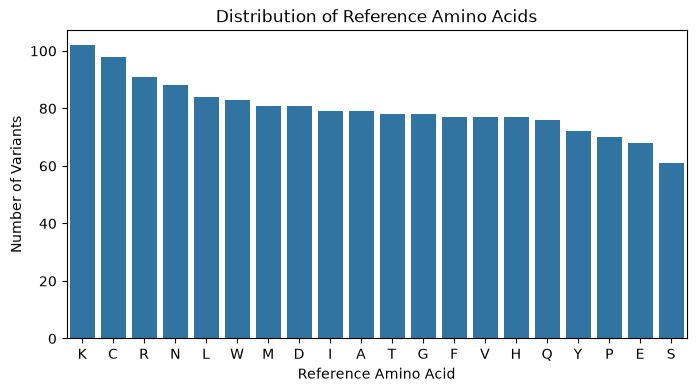

In [117]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df,x="ref_aa",order=df["ref_aa"].value_counts().index)
plt.xlabel("Reference Amino Acid")
plt.ylabel("Number of Variants")
plt.title("Distribution of Reference Amino Acids")
plt.show()

In [118]:
subs_matrix = pd.crosstab(df["ref_aa"],df["alt_aa"])
subs_matrix

alt_aa,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
ref_aa,,,,,,,,,,,,,,,,,,,,
A,0,3,3,3,1,3,7,0,4,4,4,7,4,7,6,5,6,3,3,6
C,4,0,6,6,5,5,6,7,5,6,6,4,4,3,6,4,6,3,5,7
D,4,1,0,3,5,2,2,6,5,3,6,6,6,6,6,3,6,4,3,4
E,2,4,7,0,2,3,2,5,3,6,3,2,3,4,2,5,3,3,6,3
F,3,7,5,2,0,2,5,5,4,4,6,7,4,3,3,3,3,3,4,4
G,5,5,5,2,2,0,3,7,7,4,2,3,2,2,2,4,5,8,6,4
H,4,2,7,3,3,7,0,5,6,4,6,4,1,2,4,6,3,2,5,3
I,8,6,2,1,3,4,4,0,8,3,5,5,3,5,4,3,3,7,3,2
K,7,5,9,2,7,4,9,5,0,2,2,4,7,4,4,7,5,9,6,4


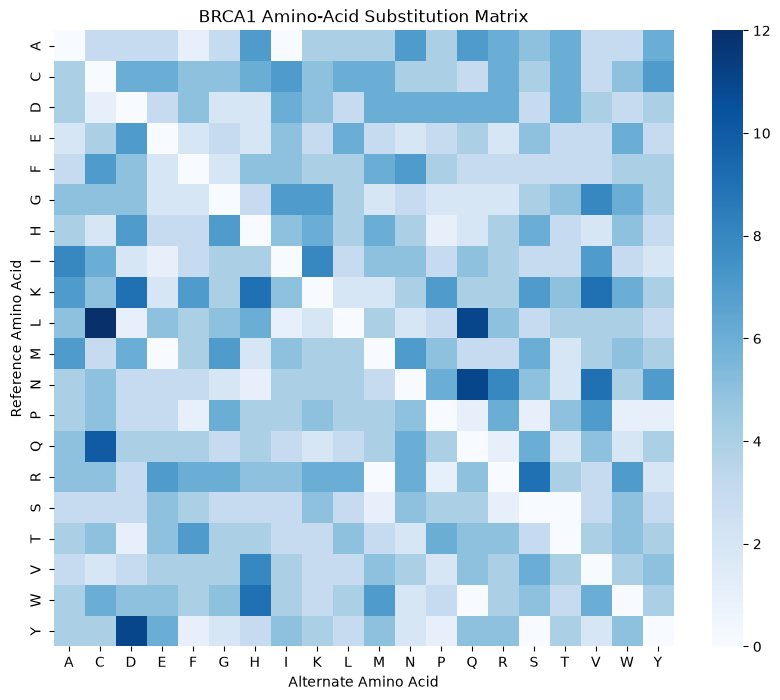

In [119]:
plt.figure(figsize=(10, 8))
sns.heatmap(subs_matrix,cmap="Blues")
plt.xlabel("Alternate Amino Acid")
plt.ylabel("Reference Amino Acid")
plt.title("BRCA1 Amino-Acid Substitution Matrix")
plt.show()

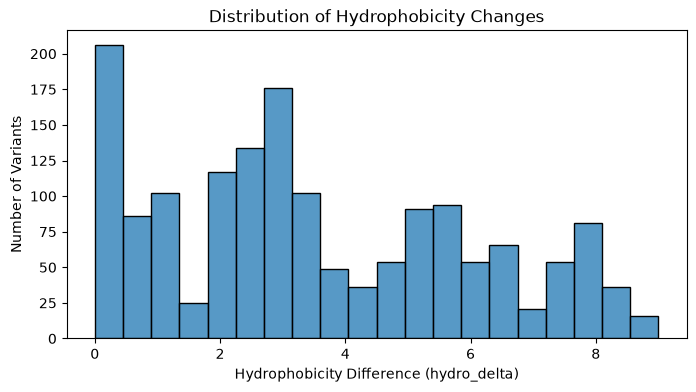

In [124]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df,x="hydro_delta",bins=20)
plt.xlabel("Hydrophobicity Difference (hydro_delta)")
plt.ylabel("Number of Variants")
plt.title("Distribution of Hydrophobicity Changes")
plt.show()

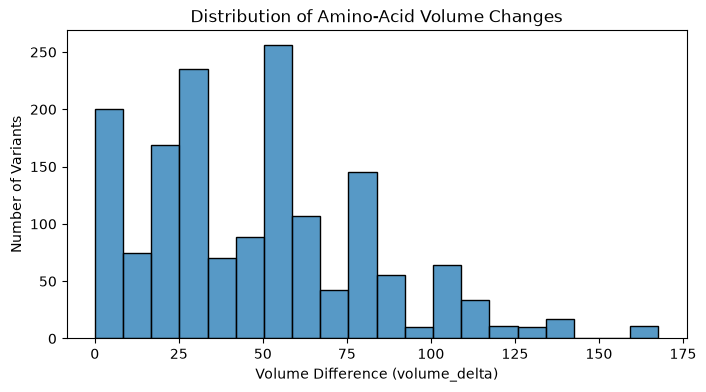

In [123]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df,x="volume_delta",bins=20)
plt.xlabel("Volume Difference (volume_delta)")
plt.ylabel("Number of Variants")
plt.title("Distribution of Amino-Acid Volume Changes")
plt.show()

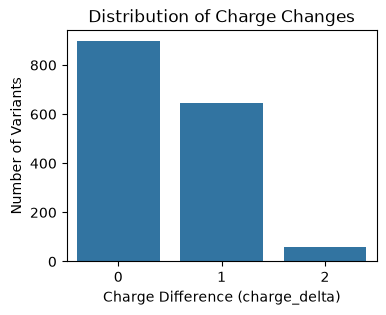

In [126]:
plt.figure(figsize=(4, 3))
sns.countplot(data=df,x="charge_delta")
plt.xlabel("Charge Difference (charge_delta)")
plt.ylabel("Number of Variants")
plt.title("Distribution of Charge Changes")
plt.show()

### Variant Flags

- `is_stop_gained`
- `is_frameshift`
- `is_splice_region`

Each feature is encoded as:

- `0` = consequence not annotated
- `1` = consequence annotated

In [127]:
for col in ["is_stop_gained", "is_frameshift", "is_splice_region"]:
    print(col)
    print(df[col].value_counts().sort_index())
    print()

is_stop_gained
is_stop_gained
0    1457
1     143
Name: count, dtype: int64

is_frameshift
is_frameshift
0    1438
1     162
Name: count, dtype: int64

is_splice_region
is_splice_region
0    1510
1      90
Name: count, dtype: int64



In [128]:
df[["is_stop_gained", "is_frameshift", "is_splice_region"]].mean().mul(100).round(1)

is_stop_gained       8.9
is_frameshift       10.1
is_splice_region     5.6
dtype: float64

In [133]:
df.loc[(df["is_stop_gained"] == 1) & (df["is_frameshift"] == 1) & (df["is_splice_region"] == 1), ["protein_change","protein_position","is_stop_gained","is_frameshift","is_splice_region"]]

,protein_change,protein_position,is_stop_gained,is_frameshift,is_splice_region
505,p.H1410I,1410,1,1,1
1222,p.C547Y,547,1,1,1


In [138]:
flag_combinations = (df.groupby(["is_stop_gained", "is_frameshift", "is_splice_region"]).size().reset_index(name="count").sort_values("count", ascending=False))
flag_combinations

,is_stop_gained,is_frameshift,is_splice_region,count
0,0,0,0,1237
2,0,1,0,140
4,1,0,0,117
1,0,0,1,76
6,1,1,0,16
5,1,0,1,8
3,0,1,1,4
7,1,1,1,2


In [136]:
flag_cols = [
    "is_stop_gained",
    "is_frameshift",
    "is_splice_region"
]

df[flag_cols].sum(axis=1).value_counts().sort_index()

0    1237
1     333
2      28
3       2
Name: count, dtype: int64

These 3 flags are not mutually exclusive

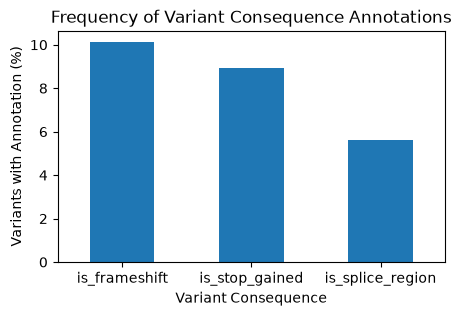

In [142]:
flag_frequency = (df[flag_cols].mean().mul(100).sort_values(ascending=False))

plt.figure(figsize=(5, 3))
flag_frequency.plot(kind="bar")
plt.ylabel("Variants with Annotation (%)")
plt.xlabel("Variant Consequence")
plt.title("Frequency of Variant Consequence Annotations")
plt.xticks(rotation=0)
plt.show()

In [143]:
df.groupby("protein_position")[["is_stop_gained", "is_frameshift", "is_splice_region"]].nunique().max()

is_stop_gained      2
is_frameshift       2
is_splice_region    2
dtype: int64

In [147]:
flag_variation = (df.groupby("protein_position")[["is_stop_gained", "is_frameshift", "is_splice_region"]].nunique())
flag_variation[(flag_variation > 1).any(axis=1)].head(5)

,is_stop_gained,is_frameshift,is_splice_region
protein_position,,,
14,1,1,2
26,1,2,1
27,1,1,2
36,1,2,1
44,1,2,1


In [148]:
position = flag_variation[(flag_variation > 1).any(axis=1)].index[0]
df.loc[df["protein_position"] == position,["protein_change","protein_position","is_stop_gained","is_frameshift","is_splice_region"]]

,protein_change,protein_position,is_stop_gained,is_frameshift,is_splice_region
1182,p.I14F,14,0,0,1
1195,p.G14V,14,0,0,0


variants occurring at the same residue can have different stop-gained, frameshift, or splice-region annotations.